# All currencies — time-varying recalibration vs benchmarks

In [50]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from ldf import ldf_func
from pit import pit_func
from utils.utils import ex_tlp

from recal_dma_new import (tvgas_pit_dma_new, convolution_recal_pit_dma_new, run_static_expanding,
                           _prep_pit, _spline_on_grid, _pit_moments, _pit_quantiles, _UN, _IVL_PROBS,
                           _interval_metrics, dm_test, _hac_lag, FEATURE_NAMES, _MIN_TRAIN)
from recal_beta_dma_new import (tvgas_pit_beta_dma_new, convolution_recal_pit_beta_dma_new,
                                run_static_expanding_beta, _bank_eval_beta)
os.makedirs('figures/fx', exist_ok=True)

## Data and the LDF pool weights (shared by all currencies)

In [52]:
exchange_rate = pd.read_excel(r'data/Y.xlsx', header=0, engine='openpyxl')
exchange_rate.rename(columns={"Unnamed: 0": "Date"}, inplace=True)
exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])

time_ind = 362
time = exchange_rate["Date"][-time_ind:]
log_lik = np.load(r"data/uip_l1_save_loglik.npz")["x"]             # joint log-likelihood, (models, T)
means = np.load(r"data/uip_l1_save_means.npz")["x"]                # (models, T, currencies)
covariance = np.load(r"data/uip_l1_save_covariance.npz")["x"]      # (models, T, currencies, currencies)

discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
c = 10**-20
res_ldf = ldf_func(log_lik.astype(float), levels=2, discount_factors=[discount_factors, discount_factors],
                   activation_functions=["softmax", "softmax"], c=c)
weights_all = res_ldf["weights"][:, -time_ind:, :]                 # (P, T, models)

CURRENCIES = list(exchange_rate.columns[1:])
assert len(CURRENCIES) == means.shape[2], "currency columns and the means array disagree"
print("currencies:", CURRENCIES)

currencies: ['AUD', 'CAD', 'EUR', 'JPY', 'NZD', 'NOK', 'SEK', 'CHF', 'GBP']


## Settings — one configuration for every currency and method

The same values as `fx_recal.ipynb`, so GBP here reproduces that notebook's main specification.

In [53]:
K            = 4
WARMUP       = 60
EVAL_START   = WARMUP + _MIN_TRAIN
ALPHA, FLOOR = 0.9, 1e-3
REFIT, HIDDEN, EPOCHS, LR, SEED = 80, 4, 200, 1e-3, 42
STATIC_REFIT = 80
ROLL_WINDOWS = (60, 120)
ABLATIONS    = True       # network only / linear head / no median_loc, per currency
ALL_DELTAS   = False      # True: all 12 discount factors (about 12x slower)
GRID_SD      = 1          # x-grid margin in s.d. of the largest component variance (as in your FX notebook)
M_GRID       = 181

D_MAIN = int(np.argmin(np.abs(discount_factors - 0.9)))
D_RUN = list(range(len(discount_factors))) if ALL_DELTAS else [D_MAIN]
RES_DIR = 'results/fx_results'; os.makedirs(RES_DIR, exist_ok=True)
SL = slice(EVAL_START, time_ind)

## One currency

In [54]:
def build_pool(ccy):
    ci = CURRENCIES.index(ccy)
    mu = means[:, :, ci][:, -time_ind:]
    var = covariance[:, :, ci, ci][:, -time_ind:]
    y = exchange_rate[ccy][-time_ind:].to_numpy(float)
    margin = GRID_SD * np.sqrt(var.max())
    x_grid = np.linspace(mu.min() - margin, mu.max() + margin, M_GRID)
    pool = ex_tlp(mu, var, x_grid, weights_all)                    # (P, T, M)
    pit = pit_func(pool, x_grid, y)                                # (P, T)
    outside = float(np.mean((y < x_grid[0]) | (y > x_grid[-1])))
    return mu, var, y, x_grid, pool, pit, outside


def score_static(kind, path, cdf_rows, x_grid, y):
    T = len(y); crps = np.zeros(T); q = np.zeros((T, 2))
    for t in range(T):
        if kind == 'rqs':
            tau, dtau = _spline_on_grid(path[t], K)
        else:
            tau, dtau = _bank_eval_beta(path[t][None, :], _UN, np.array([1.0]))
        _, crps[t] = _pit_moments(cdf_rows[t], x_grid, y[t], tau, dtau)
        q[t] = _pit_quantiles(cdf_rows[t], x_grid, tau, _IVL_PROBS)
    return crps, q


def model_entry(ll, v_eval, crps, q):
    return dict(ll=np.asarray(ll, float), v=np.asarray(v_eval, float), crps=np.asarray(crps, float),
                q=np.asarray(q, float))


def res_entry(r):
    return model_entry(r['log_likelihood'], r['calibrated_pits'], r['crps_history'],
                       np.column_stack([r['y_calibrated_q05'], r['y_calibrated_q95']]))


def run_currency(ccy):
    # every model at every delta in D_RUN; results are per-period arrays on the full sample
    path = os.path.join(RES_DIR, f"{ccy}.pkl")
    if os.path.exists(path):
        with open(path, 'rb') as fh:
            return pickle.load(fh)
    mu, var, y, x_grid, pool, pit, outside = build_pool(ccy)
    out = {'ccy': ccy, 'y': y, 'outside_grid': outside, 'deltas': {}}
    for d in D_RUN:
        sub = dict(x=x_grid, y=y, pit_data=pit[d:d + 1], cdf_data=pool[d:d + 1],
                   discount_factors=discount_factors[d:d + 1], warmup=WARMUP, eval_start=EVAL_START,
                   alpha=ALPHA, floor=FLOOR)
        net = dict(refit_every=REFIT, hidden_size=HIDDEN, num_epochs=EPOCHS, learning_rate=LR, seed=SEED)
        rg = tvgas_pit_dma_new(K=K, **sub, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)[0]
        rc = convolution_recal_pit_dma_new(K=K, **sub, **net, verbose=False)[0]
        bg = tvgas_pit_beta_dma_new(**sub, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)[0]
        bc = convolution_recal_pit_beta_dma_new(**sub, **net, verbose=False)[0]
        u = _prep_pit(pit[d])
        q_raw = np.column_stack([rg['y_raw_q05'], rg['y_raw_q95']])
        M = {'Raw pool': model_entry(np.zeros(len(y)), u[SL], rg['crps_raw_history'], q_raw),
             'RQS-GAS': res_entry(rg), 'RQS-Con': res_entry(rc),
             'Beta-GAS': res_entry(bg), 'Beta-Con': res_entry(bc)}
        for name, kind, ll, v, p in [('Static-RQS (exp)', 'rqs', rg['ll_static'], rg['v_static'], rg['theta_static']),
                                     ('Static-Beta (exp)', 'beta', bg['ll_static'], bg['v_static'], bg['logits_static'])]:
            M[name] = model_entry(ll, v[SL], *score_static(kind, p, pool[d], x_grid, y))
        for w in ROLL_WINDOWS:
            ll, p, v = run_static_expanding(u, K, WARMUP, refit_every=STATIC_REFIT, window=w)
            M[f'Static-RQS (roll {w})'] = model_entry(ll, v[SL], *score_static('rqs', p, pool[d], x_grid, y))
            ll, p, v = run_static_expanding_beta(u, WARMUP, refit_every=STATIC_REFIT, window=w)
            M[f'Static-Beta (roll {w})'] = model_entry(ll, v[SL], *score_static('beta', p, pool[d], x_grid, y))
        if ABLATIONS:
            no_loc = [f for f in FEATURE_NAMES if f != 'median_loc']
            for lab, extra in [('network only', dict(outer='none')), ('linear head', dict(hidden_size=0)),
                               ('no median_loc', dict(features=no_loc))]:
                M[f'RQS-Con: {lab}'] = res_entry(convolution_recal_pit_dma_new(K=K, **sub, **{**net, **extra}, verbose=False)[0])
                M[f'Beta-Con: {lab}'] = res_entry(convolution_recal_pit_beta_dma_new(**sub, **{**net, **extra}, verbose=False)[0])
        out['deltas'][float(discount_factors[d])] = M
    with open(path, 'wb') as fh:
        pickle.dump(out, fh)
    return out

## Run every currency (cached)

In [55]:
%%time
RESULTS = {}
for ccy in CURRENCIES:
    RESULTS[ccy] = run_currency(ccy)
    print(f"{ccy}: done  (share of outcomes outside the x-grid: {RESULTS[ccy]['outside_grid']:.1%})")

AUD: done  (share of outcomes outside the x-grid: 0.0%)
CAD: done  (share of outcomes outside the x-grid: 0.0%)
EUR: done  (share of outcomes outside the x-grid: 0.0%)
JPY: done  (share of outcomes outside the x-grid: 0.0%)
NZD: done  (share of outcomes outside the x-grid: 0.0%)
NOK: done  (share of outcomes outside the x-grid: 0.0%)
SEK: done  (share of outcomes outside the x-grid: 0.0%)
CHF: done  (share of outcomes outside the x-grid: 0.0%)
GBP: done  (share of outcomes outside the x-grid: 0.0%)
CPU times: user 1.64 ms, sys: 3.77 ms, total: 5.41 ms
Wall time: 20.7 ms


If any currency has a noticeable share of outcomes outside the x-grid, its PITs are clipped at 0 or 1. Increase `GRID_SD` (e.g. to 5), delete `results/fx_results/`, and re-run.

## Per-currency results at $\delta = 0.9$

Same columns as the main table of `fx_recal.ipynb`: gains over the raw pool with HAC DM *t* (negative = significantly worse), interval width and coverage (sharpness), KS, the dependence-robust moment test, and the tests against the static map (same family) and against GAS.

In [56]:
def dm_t(d):
    d = np.asarray(d, float)
    return dm_test(d, hac_lag=_hac_lag(len(d)))[2]

def raw_moment_test(v, n_mom=4):
    v = np.asarray(v, float)
    m = np.column_stack([v ** k - 1.0 / (k + 1) for k in range(1, n_mom + 1)])
    n = len(v); mbar = m.mean(0); e = m - mbar; L = _hac_lag(n)
    S = e.T @ e / n
    for l in range(1, L + 1):
        G = e[l:].T @ e[:-l] / n
        S += (1 - l / (L + 1)) * (G + G.T)
    stat = float(n * mbar @ np.linalg.solve(S, mbar))
    return stat, float(stats.chi2.sf(stat, n_mom))

def table_for(res, delta):
    M = res['deltas'][float(delta)]; y = res['y']; raw = M['Raw pool']
    ivl_raw = _interval_metrics(raw['q'], y, SL)
    rows = {}
    for name, e in M.items():
        ivl = _interval_metrics(e['q'], y, SL)
        fam_static = 'Static-RQS (exp)' if name.startswith('RQS') else 'Static-Beta (exp)'
        gas = 'RQS-GAS' if name.startswith('RQS') else 'Beta-GAS'
        rows[name] = {
            'ΔLogS': e['ll'][SL].mean(), 't LogS': dm_t(e['ll'][SL]) if name != 'Raw pool' else np.nan,
            'ΔCRPS %': 100 * (1 - e['crps'][SL].mean() / raw['crps'][SL].mean()),
            't CRPS': dm_t(raw['crps'][SL] - e['crps'][SL]) if name != 'Raw pool' else np.nan,
            'ΔIS90 %': 100 * (1 - ivl['score'] / ivl_raw['score']),
            't IS90': dm_t(ivl_raw['per_obs_score'] - ivl['per_obs_score']) if name != 'Raw pool' else np.nan,
            'Width/raw': ivl['width'] / ivl_raw['width'], 'Coverage': ivl['coverage'],
            'KS': stats.kstest(e['v'], 'uniform').statistic, 'Moment p': raw_moment_test(e['v'])[1],
            't vs static': dm_t(e['ll'][SL] - M[fam_static]['ll'][SL]) if name.endswith('GAS') else np.nan,
            't vs GAS': dm_t(e['ll'][SL] - M[gas]['ll'][SL]) if 'Con' in name else np.nan}
    return pd.DataFrame(rows).T

delta = float(discount_factors[D_MAIN])
TABLES = {ccy: table_for(RESULTS[ccy], delta) for ccy in CURRENCIES}
ALL = pd.concat(TABLES, names=['currency', 'model'])
ALL.style.format(precision=3)

## Across currencies: how often does each model help or hurt?

For each model, the number of currencies in which its gain over the raw pool is significantly positive or negative at 5% (HAC DM), for the log score, CRPS and interval score; the number passing the moment test; and the mean coverage and width. The second table counts how often GAS beats the static map of its family, and the composition beats GAS.

In [57]:
crit = 1.96
summ = ALL.groupby(level='model', sort=False).agg(
    **{'LogS better': ('t LogS', lambda s: int((s > crit).sum())),
       'LogS worse':  ('t LogS', lambda s: int((s < -crit).sum())),
       'CRPS better': ('t CRPS', lambda s: int((s > crit).sum())),
       'CRPS worse':  ('t CRPS', lambda s: int((s < -crit).sum())),
       'IS90 better': ('t IS90', lambda s: int((s > crit).sum())),
       'IS90 worse':  ('t IS90', lambda s: int((s < -crit).sum())),
       'moment pass': ('Moment p', lambda s: int((s > 0.05).sum())),
       'mean ΔLogS':  ('ΔLogS', 'mean'),
       'mean coverage': ('Coverage', 'mean'),
       'mean width/raw': ('Width/raw', 'mean')})
summ.insert(0, 'currencies', len(CURRENCIES))
summ.style.format(precision=3)

,currencies,LogS better,LogS worse,CRPS better,CRPS worse,IS90 better,IS90 worse,moment pass,mean ΔLogS,mean coverage,mean width/raw
model,,,,,,,,,,,
Raw pool,9,0,0,0,0,0,0,5,0.000,0.917,1.000
RQS-GAS,9,0,0,0,0,1,0,8,-0.007,0.909,0.974
RQS-Con,9,0,2,0,1,0,0,8,-0.019,0.904,0.962
Beta-GAS,9,0,0,0,1,0,0,9,-0.003,0.896,0.931
Beta-Con,9,0,0,0,2,0,0,8,-0.008,0.892,0.930
Static-RQS (exp),9,0,5,0,0,1,0,9,-0.039,0.895,0.923
Static-Beta (exp),9,0,1,0,1,1,0,8,-0.006,0.893,0.933
Static-RQS (roll 60),9,0,9,0,4,0,0,9,-0.153,0.893,0.934
Static-Beta (roll 60),9,0,1,0,1,0,1,7,-0.019,0.895,0.948


In [58]:
comp = pd.DataFrame({
    'GAS > static (sig.)': ALL['t vs static'].groupby(level='model', sort=False).apply(lambda s: int((s > crit).sum())),
    'GAS < static (sig.)': ALL['t vs static'].groupby(level='model', sort=False).apply(lambda s: int((s < -crit).sum())),
    'Con > GAS (sig.)': ALL['t vs GAS'].groupby(level='model', sort=False).apply(lambda s: int((s > crit).sum())),
    'Con < GAS (sig.)': ALL['t vs GAS'].groupby(level='model', sort=False).apply(lambda s: int((s < -crit).sum())),
})
comp[(comp.sum(axis=1) > 0) | comp.index.str.contains('GAS|Con')]

,GAS > static (sig.),GAS < static (sig.),Con > GAS (sig.),Con < GAS (sig.)
model,,,,
RQS-GAS,4,0,0,0
RQS-Con,0,0,0,2
Beta-GAS,0,0,0,0
Beta-Con,0,0,0,0
RQS-Con: network only,0,0,1,0
Beta-Con: network only,0,0,0,0
RQS-Con: linear head,0,0,0,0
Beta-Con: linear head,0,0,1,0
RQS-Con: no median_loc,0,0,0,0


In [59]:
def summary_latex(summ, caption, label):
    cols = ['LogS better', 'LogS worse', 'CRPS better', 'CRPS worse', 'IS90 better', 'IS90 worse',
            'moment pass', 'mean coverage', 'mean width/raw']
    head = (r"Model & \multicolumn{2}{c}{LogS} & \multicolumn{2}{c}{CRPS} & \multicolumn{2}{c}{IS$_{90}$} "
            r"& Moment & Cov. & Width/raw \\ \cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}"
            r" & $+$ & $-$ & $+$ & $-$ & $+$ & $-$ & pass & & \\")
    lines = [r"\begin{table}[H]", r"\centering", r"\small", r"\begin{tabular}{l cccccc c cc}", r"\toprule",
             head, r"\midrule"]
    for name, r in summ.iterrows():
        cells = [str(int(r[c])) for c in cols[:7]] + [f"{r['mean coverage']:.2f}", f"{r['mean width/raw']:.2f}"]
        lines.append(f"{name} & " + " & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    print("\n".join(lines))

summary_latex(summ.drop(index=[i for i in summ.index if ':' in i]),
              caption=(rf"Exchange rates, {len(CURRENCIES)} currencies, $\delta={delta}$: number of currencies in "
                       r"which each model's gain over the raw LDF$^2_{s,s}$ pool is significantly positive ($+$) "
                       r"or negative ($-$) at 5\% (HAC Diebold--Mariano test), number passing the dependence-robust "
                       r"moment test, and mean coverage and relative width of the central 90\% interval."),
              label="tab:fx-all")

\begin{table}[H]
\centering
\small
\begin{tabular}{l cccccc c cc}
\toprule
Model & \multicolumn{2}{c}{LogS} & \multicolumn{2}{c}{CRPS} & \multicolumn{2}{c}{IS$_{90}$} & Moment & Cov. & Width/raw \\ \cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7} & $+$ & $-$ & $+$ & $-$ & $+$ & $-$ & pass & & \\
\midrule
Raw pool & 0 & 0 & 0 & 0 & 0 & 0 & 5 & 0.92 & 1.00 \\
RQS-GAS & 0 & 0 & 0 & 0 & 1 & 0 & 8 & 0.91 & 0.97 \\
RQS-Con & 0 & 2 & 0 & 1 & 0 & 0 & 8 & 0.90 & 0.96 \\
Beta-GAS & 0 & 0 & 0 & 1 & 0 & 0 & 9 & 0.90 & 0.93 \\
Beta-Con & 0 & 0 & 0 & 2 & 0 & 0 & 8 & 0.89 & 0.93 \\
Static-RQS (exp) & 0 & 5 & 0 & 0 & 1 & 0 & 9 & 0.90 & 0.92 \\
Static-Beta (exp) & 0 & 1 & 0 & 1 & 1 & 0 & 8 & 0.89 & 0.93 \\
Static-RQS (roll 60) & 0 & 9 & 0 & 4 & 0 & 0 & 9 & 0.89 & 0.93 \\
Static-Beta (roll 60) & 0 & 1 & 0 & 1 & 0 & 1 & 7 & 0.89 & 0.95 \\
Static-RQS (roll 120) & 0 & 6 & 0 & 3 & 0 & 1 & 9 & 0.90 & 0.95 \\
Static-Beta (roll 120) & 0 & 0 & 0 & 1 & 0 & 1 & 7 & 0.90 & 0.95 \\
\bottomrule
\end{tabular}
\

## Figure: log-score gain by currency

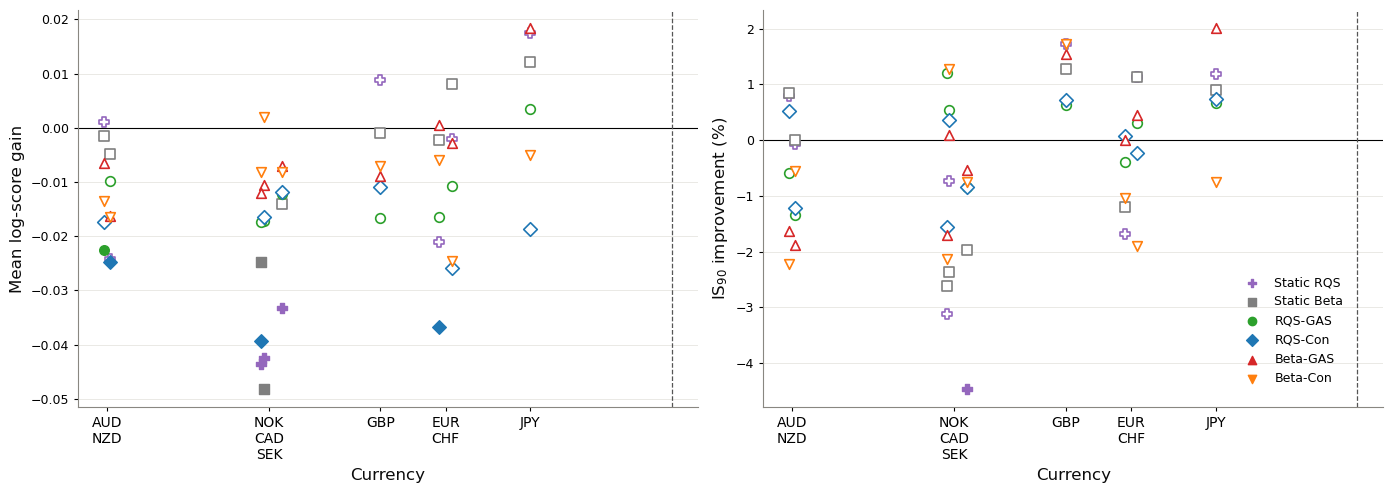

,raw KS,raw KS p,ΔLogS Static-RQS (exp),ΔLogS Static-Beta (exp),ΔLogS RQS-GAS,ΔLogS RQS-Con,ΔLogS Beta-GAS,ΔLogS Beta-Con
AUD,0.043,0.685,-0.028,-0.010,-0.009,-0.024,-0.005,-0.002
NZD,0.043,0.674,-0.057,-0.014,-0.013,-0.028,-0.012,-0.023
NOK,0.054,0.397,-0.045,-0.015,-0.011,-0.017,-0.010,0.001
CAD,0.054,0.392,-0.053,-0.026,-0.012,-0.014,-0.006,0.007
SEK,0.055,0.365,-0.064,-0.009,-0.012,-0.043,-0.006,-0.022
GBP,0.062,0.235,-0.025,0.006,-0.007,-0.003,-0.005,-0.003
EUR,0.066,0.176,-0.044,-0.002,-0.010,-0.033,0.001,-0.019
CHF,0.067,0.165,-0.022,0.008,-0.006,-0.032,0.000,-0.019
JPY,0.073,0.108,-0.013,0.009,0.014,0.021,0.016,0.004


In [143]:
KEY = {'Static-RQS (exp)': 'rs', 'Static-Beta (exp)': 'bs', 'RQS-GAS': 'rg',
       'RQS-Con': 'rc', 'Beta-GAS': 'bg', 'Beta-Con': 'bc'}
dkey = round(float(discount_factors[D_MAIN]), 6)

def _loc(c):
    return FX_LOC[c]['localized'][dkey]

def gain_and_sig(c, row, m, pct=False):
    """Gain of method m on `row` from the scorecard (same numbers as the table),
    and whether it has at least two stars (significant at 5%)."""
    r = _loc(c)[row]
    s = r['gain'][KEY[m]]
    g = float(s.replace('*', '').replace('$', '').replace('^', '').replace('{', '').replace('}', ''))
    if pct:
        g = 100 * g / r['raw']
    return g, s.count('*') >= 2

xs = np.array([_loc(c)['ks']['raw'] for c in CURRENCIES])     # raw-pool KS, as in the table
n_eval = _loc(CURRENCIES[0])['n']
crit_ks = 1.36 / np.sqrt(n_eval)

# x-axis ticks at each currency's position; names closer than `gap` share one tick, stacked
span = xs.max() - xs.min()
gap = 0.06 * span
order = np.argsort(xs)
groups = [[order[0]]]
for i in order[1:]:
    if xs[i] - xs[groups[-1][-1]] < gap:
        groups[-1].append(i)
    else:
        groups.append([i])
tick_pos = [xs[g].mean() for g in groups]
tick_lab = ['\n'.join(CURRENCIES[i] for i in g) for g in groups]
xlo = min(xs.min(), crit_ks) - 0.06 * span             # keep the critical value in view
xhi = max(xs.max(), crit_ks) + 0.06 * span

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
panels = [('logs', False, 'Mean log-score gain'),
          ('is90', True, r'$\mathrm{IS}_{90}$ improvement (%)')]
for ax, (row, pct, lab) in zip(axes, panels):
    for m, c_, mk in zip(show, colors, markers):
        gs = [gain_and_sig(c, row, m, pct) for c in CURRENCIES]
        ys = np.array([g for g, _ in gs])
        sig = np.array([s for _, s in gs])
        ax.scatter(xs[~sig], ys[~sig], marker=mk, facecolors='white', edgecolors=c_, s=48, lw=1.2, zorder=3)
        ax.scatter(xs[sig], ys[sig], marker=mk, color=c_, s=48, zorder=4)
        name = m.replace(' (exp)', '').replace('Static-', 'Static ')
        ax.scatter([], [], marker=mk, color=c_, label=f"{name}")# (ρ = {rho:+.2f})")
    ax.axhline(0, color='black', lw=0.8)
    ax.axvline(crit_ks, color='#555555', lw=0.9, ls='--')
    ax.set_xlim(xlo, xhi)
    ax.set_xticks(tick_pos, tick_lab, fontsize=10,color='black')
    ax.tick_params(axis='both', length=3,color='black',labelcolor='black')
    ax.set_xlabel("Currency",fontsize=12)
    ax.set_ylabel(lab,fontsize=12)
    ax.grid(axis='y', color='#e6e5e1', lw=0.6)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    

h, l = axes[0].get_legend_handles_labels()
h += [plt.Line2D([], [], marker='o', ls='', mfc='#444444', mec='#444444'),
      plt.Line2D([], [], marker='o', ls='', mfc='white', mec='#444444'),
      plt.Line2D([], [], color='#555555', ls='--'),
      plt.Rectangle((0, 0), 1, 1, color='#f3f2ee')]
#l += ['significant at 5%', 'not significant', '5% KS critical value']
fig.legend(h, l, ncol=1, frameon=False, fontsize=9, loc='lower right', bbox_to_anchor=(0.97, 0.2))
fig.tight_layout()
fig.savefig('figures/fx/gain_vs_miscalibration.pdf', bbox_inches='tight',dpi=600)
plt.show()

pd.DataFrame({'raw KS': raw_stat,
              'raw KS p': {c: stats.kstest(RESULTS[c]['deltas'][delta]['Raw pool']['v'], 'uniform').pvalue
                           for c in CURRENCIES},
              **{f'ΔLogS {m}': {c: TABLES[c].loc[m, 'ΔLogS'] for c in CURRENCIES} for m in show}}) \
  .sort_values('raw KS').style.format(precision=3)

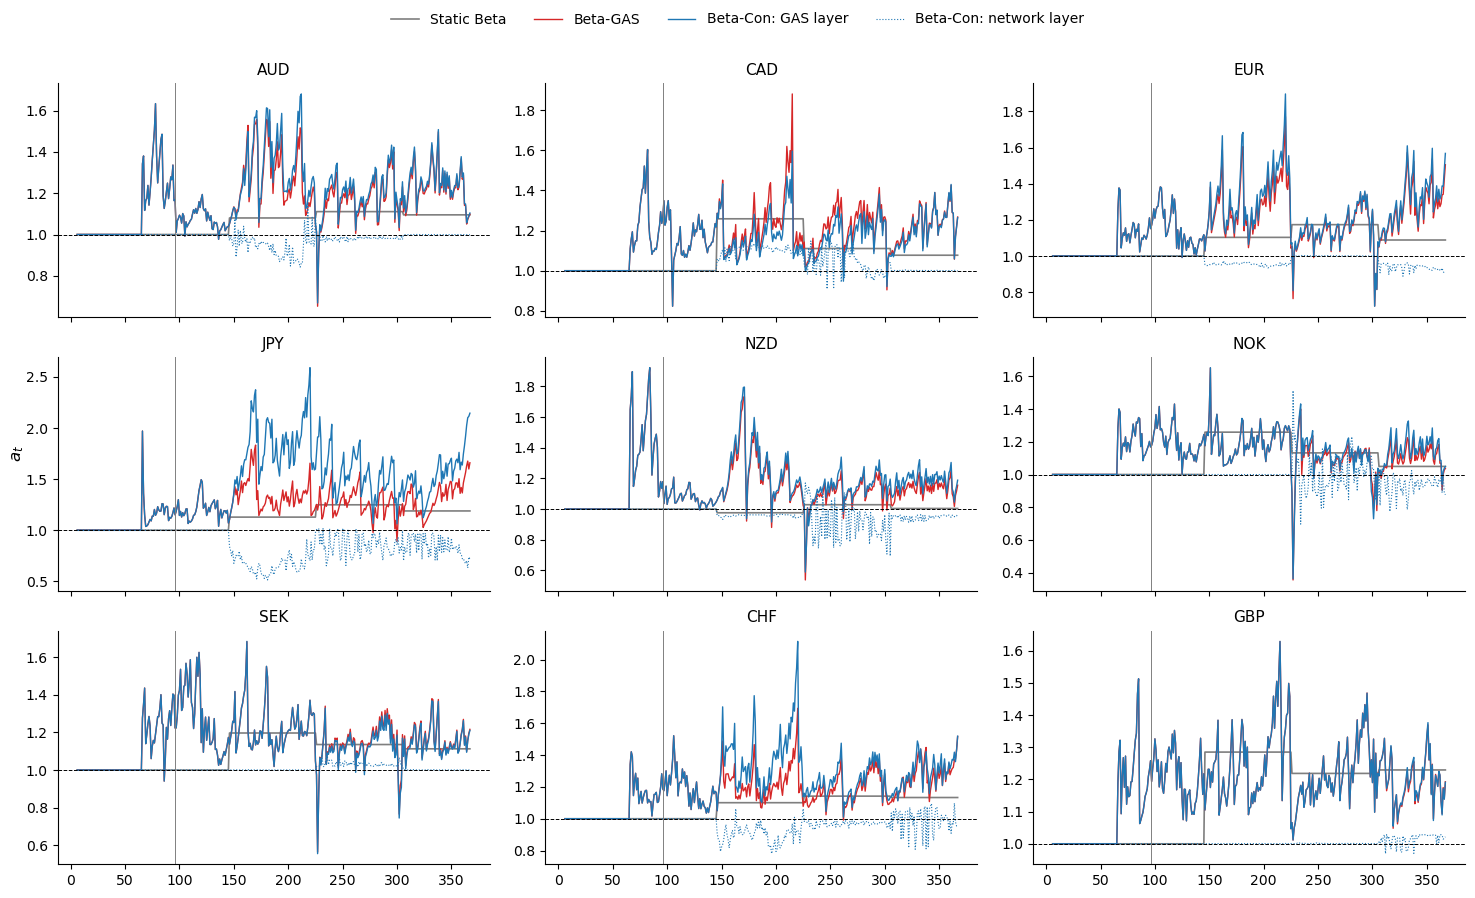

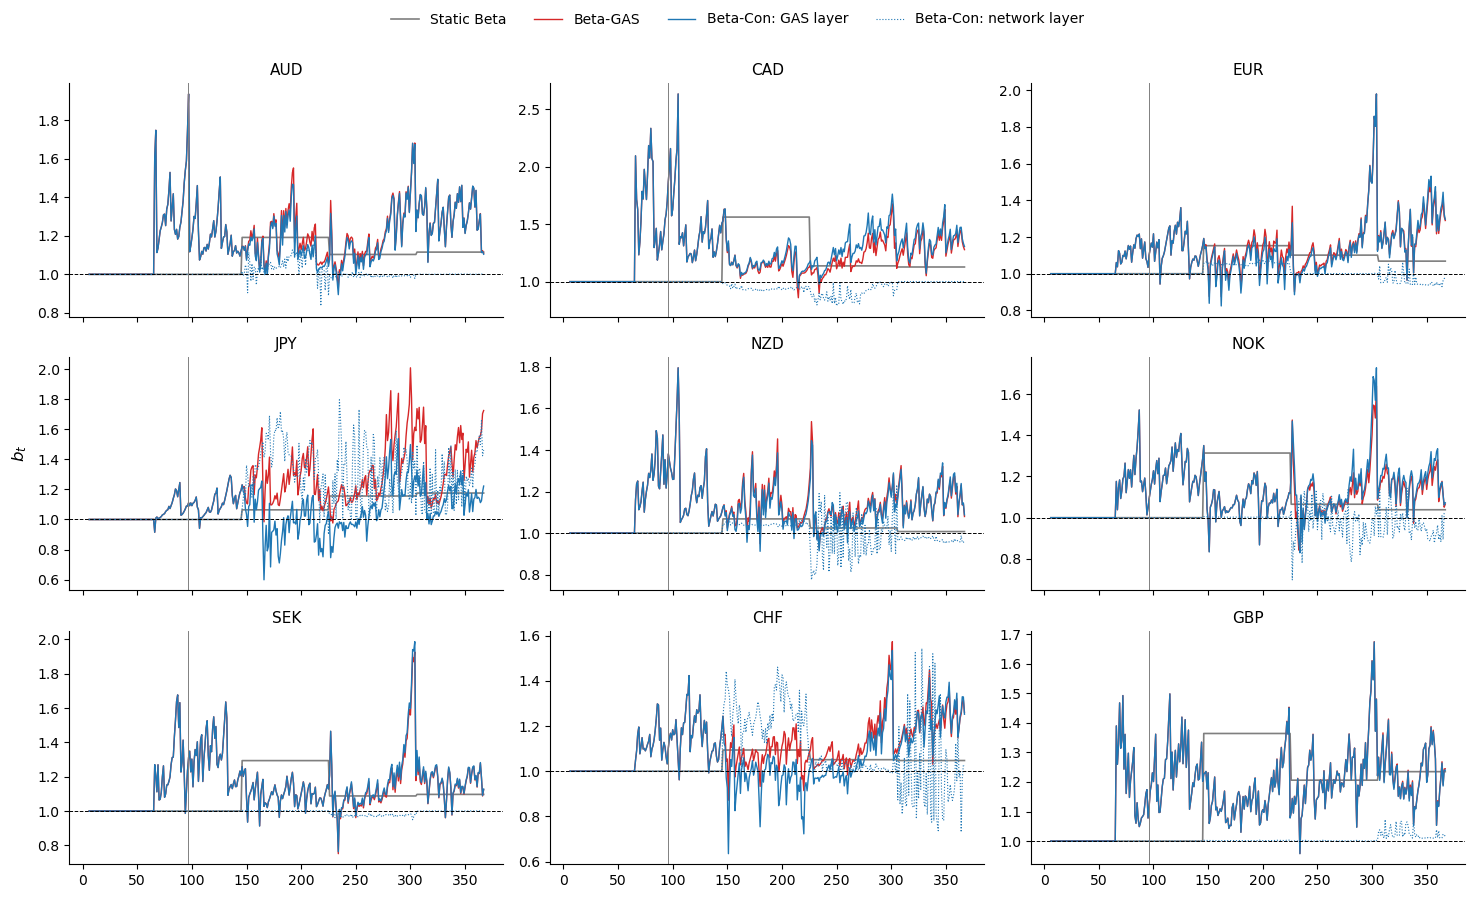

In [62]:
from recal_beta_dma_new import _ab

AB_DIR = os.path.join(RES_DIR, 'beta_paths'); os.makedirs(AB_DIR, exist_ok=True)

def beta_paths(ccy, d=D_MAIN):
    """Actual Beta parameters for static Beta, Beta-GAS and the Beta-Con GAS and network layers.
    Same settings as run_currency, so the paths belong to the results in RESULTS."""
    path = os.path.join(AB_DIR, f"{ccy}_{d}.pkl")
    if os.path.exists(path):
        with open(path, 'rb') as fh:
            return pickle.load(fh)
    mu, var, y, x_grid, pool, pit, outside = build_pool(ccy)
    sub = dict(x=x_grid, y=y, pit_data=pit[d:d + 1], cdf_data=pool[d:d + 1],
               discount_factors=discount_factors[d:d + 1], warmup=WARMUP, eval_start=EVAL_START,
               alpha=ALPHA, floor=FLOOR)
    net = dict(refit_every=REFIT, hidden_size=HIDDEN, num_epochs=EPOCHS, learning_rate=LR, seed=SEED)
    bg = tvgas_pit_beta_dma_new(**sub, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)[0]
    bc = convolution_recal_pit_beta_dma_new(**sub, **net, verbose=False)[0]
    a_st, b_st = _ab(bg['logits_static'][:, 0], bg['logits_static'][:, 1])   # logits -> (a, b)
    out = {'static': (a_st, b_st), 'gas': (bg['a_path'], bg['b_path']),
           'con_gas': (bc['a_gas'], bc['b_gas']), 'con_nn': (bc['a_nn'], bc['b_nn'])}
    with open(path, 'wb') as fh:
        pickle.dump(out, fh)
    return out

AB = {ccy: beta_paths(ccy) for ccy in CURRENCIES}

dates = exchange_rate.index[-time_ind:]
def plot_ab(param, fname):
    j = 0 if param == 'a' else 1
    fig, axes = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
    for ax, ccy in zip(axes.flat, CURRENCIES):
        P = AB[ccy]
        ax.plot(dates, P['static'][j], color='#7f7f7f', lw=1.2, label='Static Beta')
        ax.plot(dates, P['gas'][j], color='#d62728', lw=1.0, label='Beta-GAS')
        ax.plot(dates, P['con_gas'][j], color='#1f77b4', lw=1.0, label='Beta-Con: GAS layer')
        ax.plot(dates, P['con_nn'][j], color='#1f77b4', lw=0.8, ls=':', label='Beta-Con: network layer')
        ax.axhline(1, color='k', lw=0.7, ls='--')
        ax.axvline(dates[EVAL_START], color='grey', lw=0.7)
        ax.set_title(ccy, fontsize=11)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, ncol=4, frameon=False, loc='upper center', fontsize=10)
    fig.supylabel(f'${param}_t$')
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(f'figures/fx/{fname}', bbox_inches='tight')
    plt.show()

plot_ab('a', 'beta_a_all_currencies.pdf')
plot_ab('b', 'beta_b_all_currencies.pdf')

In [68]:
from uniformity_tests import uniformity_test
from scipy import stats

TEST_COLS = [("KS_Test", "KS"), ("AD_Test", "AD"), ("Chi2_Test", r"$\chi^2$"),
             ("DH_Test", "DH"), ("LB_Test", "LB"), ("Berkowitz_Test", "Berk.")]
SHOW = ["Raw pool", "Static-RQS (exp)", "RQS-GAS", "RQS-Con", "Static-Beta (exp)", "Beta-GAS", "Beta-Con"]

def tests_for(v, delta):
    _, summ = uniformity_test(np.asarray(v, float)[None, :], [delta])
    return {lab: str(summ[col].iloc[0]).strip().upper() == "PASS" for col, lab in TEST_COLS}

PASS = {}            # (currency, model) -> {test: bool}
for c in CURRENCIES:
    M = RESULTS[c]["deltas"][delta]
    for m in SHOW:
        PASS[(c, m)] = tests_for(M[m]["v"], delta)

uni = ["KS", "AD", r"$\chi^2$", "DH",'LB','Berk.']
tab = pd.DataFrame({m: {c: sum(PASS[(c, m)][t] for t in uni) for c in CURRENCIES} for m in SHOW})
#tab.loc["Currencies passing all six"] = [(tab[m] == 6).sum() for m in SHOW]
tab                                   # uniformity tests passed (of 6) per currency

,Raw pool,Static-RQS (exp),RQS-GAS,RQS-Con,Static-Beta (exp),Beta-GAS,Beta-Con
AUD,5,6,6,6,6,6,6
CAD,5,5,5,5,5,5,6
EUR,5,5,5,5,5,5,5
JPY,2,5,5,5,5,5,5
NZD,6,6,6,6,6,6,6
NOK,5,6,6,6,5,6,6
SEK,6,6,6,6,6,6,6
CHF,4,5,5,5,5,4,5
GBP,4,6,4,5,5,4,4


In [76]:
def fx_tests_latex(tab, label="tab:fx-tests"):
    """Rows: methods; columns: currencies."""
    L = [r"\begin{table}[H]\centering\small",
         r"\begin{tabular}{l" + "c" * len(CURRENCIES) + r"}\toprule",
         "Method & " + " & ".join(CURRENCIES) + r" \\ \midrule"]
    for k, m in enumerate(SHOW):
        if k in (1, 4):                               # raw | RQS block | Beta block
            L.append(r"\midrule")
        L.append(f"{m} & " + " & ".join(str(int(tab.loc[c, m])) for c in CURRENCIES) + r" \\")
    L += [r"\bottomrule\end{tabular}",
          rf"\caption{{Exchange rates, $\delta={delta}$: number of the four uniformity tests (KS, "
          r"Anderson--Darling, $\chi^2$, Dawid--Sebastiani) that do not reject at 5\% for each currency.}",
          rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(L)

print(fx_tests_latex(tab))

\begin{table}[H]\centering\small
\begin{tabular}{lccccccccc}\toprule
Method & AUD & CAD & EUR & JPY & NZD & NOK & SEK & CHF & GBP \\ \midrule
Raw pool & 5 & 5 & 5 & 2 & 6 & 5 & 6 & 4 & 4 \\
\midrule
Static-RQS (exp) & 6 & 5 & 5 & 5 & 6 & 6 & 6 & 5 & 6 \\
RQS-GAS & 6 & 5 & 5 & 5 & 6 & 6 & 6 & 5 & 4 \\
RQS-Con & 6 & 5 & 5 & 5 & 6 & 6 & 6 & 5 & 5 \\
\midrule
Static-Beta (exp) & 6 & 5 & 5 & 5 & 6 & 5 & 6 & 5 & 5 \\
Beta-GAS & 6 & 5 & 5 & 5 & 6 & 6 & 6 & 4 & 4 \\
Beta-Con & 6 & 6 & 5 & 5 & 6 & 6 & 6 & 5 & 4 \\
\bottomrule\end{tabular}
\caption{Exchange rates, $\delta=0.9$: number of the four uniformity tests (KS, Anderson--Darling, $\chi^2$, Dawid--Sebastiani) that do not reject at 5\% for each currency.}
\label{tab:fx-tests}
\end{table}


In [141]:
import sim_report as sr
from localised_metrics import evaluate_localized, static_reports

LOC_DIR = os.path.join(RES_DIR, 'loc'); os.makedirs(LOC_DIR, exist_ok=True)
d_idx = D_MAIN
delta_main = float(discount_factors[d_idx])

def localized_currency(ccy):
    path = os.path.join(LOC_DIR, f"{ccy}_{d_idx}.pkl")
    if os.path.exists(path):
        with open(path, 'rb') as fh:
            return pickle.load(fh)
    mu, var, y, x_grid, pool, pit, outside = build_pool(ccy)
    sub = dict(x=x_grid, y=y, pit_data=pit[d_idx:d_idx + 1], cdf_data=pool[d_idx:d_idx + 1],
               discount_factors=discount_factors[d_idx:d_idx + 1], warmup=WARMUP,
               eval_start=EVAL_START, alpha=ALPHA, floor=FLOOR)
    net = dict(refit_every=REFIT, hidden_size=HIDDEN, num_epochs=EPOCHS, learning_rate=LR, seed=SEED)
    rg = tvgas_pit_dma_new(K=K, **sub, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)
    rc = convolution_recal_pit_dma_new(K=K, **sub, **net, verbose=False)
    bg = tvgas_pit_beta_dma_new(**sub, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)
    bc = convolution_recal_pit_beta_dma_new(**sub, **net, verbose=False)
    loc = evaluate_localized(
        x=x_grid, y=y, pit_data=pit, cdf_data=pool,
        methods={'GAS spline': rg, 'CONV spline': rc, 'GAS beta': bg, 'CONV beta': bc,
                 'Static spline': static_reports(rg, 'rqs', K=K),
                 'Static beta': static_reports(bg, 'beta')},
        discount_factor=delta_main, eval_start=EVAL_START,
        min_events=30, n_blocks=2, verbose=False)
    entry = {"group": "", "localized": {}}
    tmp = {ccy: entry}
    sr.add_localized(tmp, ccy, loc)
    with open(path, 'wb') as fh:
        pickle.dump(tmp[ccy], fh)
    return tmp[ccy]

FX_LOC = {}
for ccy in CURRENCIES:
    FX_LOC[ccy] = localized_currency(ccy)
    print(ccy, "done")

d = sr.DELTAS.index(delta_main)
tex = sr.scorecard_latex(FX_LOC, d, caption=(
    rf"Exchange rates, LDF discount factor $\delta={delta_main:g}$, last {len(RESULTS[CURRENCIES[0]]['y']) - EVAL_START} "
    r"months. KS: Kolmogorov--Smirnov distance of the PIT from uniform ($^\dagger$ rejects at 5\%). "
    r"Raw pool: level of each score; method columns: gain over the raw pool, positive is better. "
    r"Stars: HAC Giacomini--White test at 10/5/1\%. Static RQS, Static Beta: expanding-window static "
    r"maps. Best method in bold."))
print(tex)
open("tables/fx_scores.tex", "w").write(tex)

AUD done
CAD done
EUR done
JPY done
NZD done
NOK done
SEK done
CHF done
GBP done
\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
AUD & KS & $0.043$ & $0.050$ & $0.037$ & $\mathbf{0.031}$ & $0.056$ & $0.045$ & $0.049$ \\
 & LogS & $1.8971$ & $\mathbf{+0.0011}$ & $-0.0225^{***}$ & $-0.0174^{*}$ & $-0.0015$ & $-0.0065$ & $-0.0136$ \\
 & CRPS & $0.0201$ & $-0.0001^{*}$ & $-0.0001$ & $\mathbf{-0.0000}$ & $-0.0001$ & $-0.0002$ & $-0.0003^{*}$ \\
 & IS$_{90}$ & $0.1528$ & $+0.0012$ & $-0.0009$ & $+0.0008$ & $\mathbf{+0.0013}$ & $-0.0025$ & $-0.0034$ \\
 & IS$_{95}$ & $0.1755$ & $\mathbf{+0.0027}$ & $-0.0000$ & $+0.0012$ & $+0.0015$ & $-0.0032$ & $-0.0059$ \\
 & CSL$_{L}$ & $0.0168$ & $-0.0051$ & $-0.0047$ & $\mathbf{+0.0009}$ & $-0.0032$ & $-0.0047$ & $-0.0074$ \\
 & CSL$_{R}$ & $0.1068$ & $\mathbf{+0.0029}$ & $-0.0095^{*}$ & $-0.0009$ & $-0.0035$ & $-0.0182^{**}$ 

7643